# Question 2, Part C


First Size is:	 0.100000mm
Final Size is:	 0.302143mm


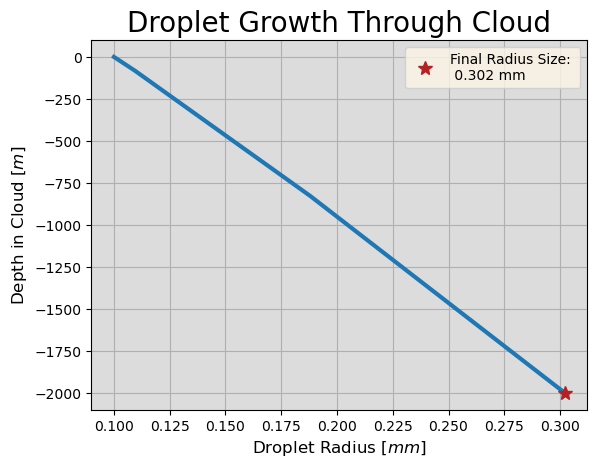

In [132]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.integrate import ode
plt.rcParams['figure.titlesize'] = 22
plt.rcParams['figure.constrained_layout.use'] = False
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.facecolor'] = 'gainsboro'
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.labelsize'] = 'large'
plt.rcParams['lines.linewidth'] = 3
plt.rcParams['legend.facecolor'] = 'oldlace'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'
plt.rcParams['axes.grid'] = True
COLOR1 = 'teal'
COLOR2 = 'sandybrown'


k_2 = 8e3 #s^-1
E_c = 0.698 #ratio
w_l = 0.5 #gm^-3
rho_l = 1e6 #gm^-3
w = 0.2 #ms^-1
r_0 = 0.1e-3 #0.00001m
z_0 = 0 #m
z_f= -2000 #m
def dr_dz(z, r):
    #Calculates dr_dt
    #v(t) is already included as k_2*r
    #print(f"itereating! r = {r}, z = {z}")
    dr_dz = ( (E_c * w_l) / (4 * rho_l) ) * ( (k_2 * r) / (w - (k_2 * r) ) )
    return dr_dz
sol = solve_ivp(dr_dz, [z_0,z_f], [r_0], method = 'DOP853')
plt.plot(sol.y[0]*1e3, sol.t )
plt.title("Droplet Growth Through Cloud")
plt.ylabel("Depth in Cloud [$m$]")
plt.xlabel("Droplet Radius [$mm$]")
plt.plot(sol.y[0][-1]*1e3, sol.t[-1], marker = '*', color = 'firebrick', label = f"Final Radius Size: \n {sol.y[0][-1]*1e3:0.3} mm",
         linestyle = 'none', markersize = 10)
plt.legend()
print(f"First Size is:\t {r_0*1e3:0.6f}mm")
print(f"Final Size is:\t {sol.y[0][-1]*1e3:.6f}mm")
